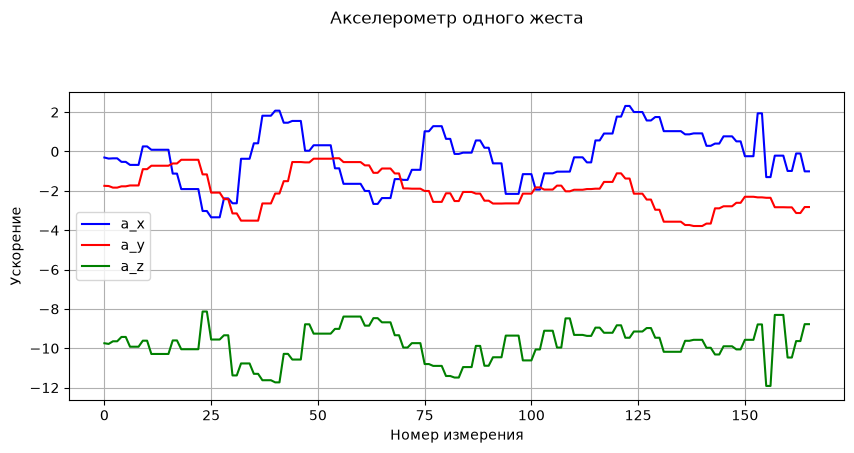

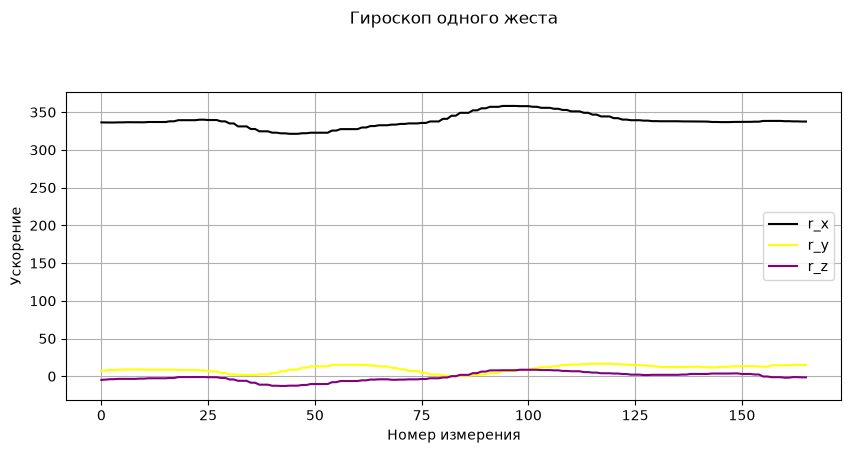

In [103]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import buttord, butter, sosfiltfilt
from scipy.ndimage import median_filter
import pandas as pd
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)
from sklearn.ensemble import IsolationForest


# собираем названия всех папок пользователй
dataset_root = Path(r"C:\Users\Даниил\IIT\task_1\data_legitimate")
user_folders = sorted([path for path in dataset_root.iterdir() if path.is_dir()])

# функция парсинга жеста из файла с номером num_file
# возвращает матрицу измерений (сигналов по горизонтали и временных рядов атрибутов по вертикали)
def get_gesture(user_folders, train_valid_test, num_user, num_file):
    # собираем итоговый путь
    result_path = user_folders[num_user] / "inf" / train_valid_test
    
    # определяем какого расширения хранятся файлы в папке
    txt_files_len = len(list(result_path.glob("*.txt")))
    json_files_len = len(list(result_path.glob("*.json")))
    if txt_files_len: txt_or_json = "*.txt" 
    else: txt_or_json = "*.json"
    
    # парсим все файлы (.txt или .json)
    gesture_files = sorted(result_path.glob(txt_or_json))
    
    # прочтали текстовый 0-ой файл как json-файл и записали его в виде словаря в file_data
    with open(gesture_files[num_file], "r", encoding = "utf-8") as file:
        file_data = json.load(file)

    if txt_or_json == "*.txt":
        # обращаемся к словарю по двум ключам и получаем все измерения
        measurements = file_data["params"]["data"]
        
        # создаем матрицу измерений размера (кол-во измерений) * 6
        time_series_matrix_list = []
        for measurement in measurements:
            # связываем конец первого и начало второго списков
            acceleration = measurement["acceleration"]
            rotation = measurement["rotation"]
            measurement_row = acceleration + rotation
            time_series_matrix_list.append(measurement_row)
    
    elif txt_or_json == "*.json":
        # будем парсить словарь измерений
        measurements = file_data
        
        # создаем матрицу измерений размера (кол-во измерений) * 6
        time_series_matrix_list = []
        for measurement in measurements:
            # связываем значения измерения в таком же порядке как и в txt
            if "x_rot" in measurement and "y_rot" in measurement and "z_rot" in measurement:
                measurement_row = [measurement["x_acc"], measurement["y_acc"],
                                measurement["z_acc"], measurement["x_rot"],
                                measurement["y_rot"], measurement["z_rot"]]
            elif "a_rot" in measurement and "b_rot" in measurement and "g_rot" in measurement:
                measurement_row = [measurement["x_acc"], measurement["y_acc"],
                                measurement["z_acc"], measurement["a_rot"],
                                measurement["b_rot"], measurement["g_rot"]]

            time_series_matrix_list.append(measurement_row)

    # преобразование типов из списка в numpy матричный класс
    time_series_matrix = np.array(time_series_matrix_list, dtype=float)
    return time_series_matrix

# парсим атрибуты (временные ряды) из матрицы для 0-ого файла
time_series_matrix = get_gesture(user_folders, "train", num_user=5, num_file=0)
a_x = time_series_matrix[:, 0]
a_y = time_series_matrix[:, 1]
a_z = time_series_matrix[:, 2]

r_x = np.unwrap(time_series_matrix[:, 3], period=360, axis=0)
r_y = np.unwrap(time_series_matrix[:, 4], period=360, axis=0)
r_z = np.unwrap(time_series_matrix[:, 5], period=360, axis=0)

# строим график временных рядов a_x, a_y, a_z (акселерометр)
plt.figure(figsize=(10, 4))

plt.plot(a_x, label="a_x", color="blue")
plt.plot(a_y, label="a_y", color="red")
plt.plot(a_z, label="a_z", color="green")

plt.title("Акселерометр одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

# строим график временных рядов r_x, r_y, r_z (гироскоп)
plt.figure(figsize=(10, 4))

plt.plot(r_x, label="r_x", color="black")
plt.plot(r_y, label="r_y", color="yellow")
plt.plot(r_z, label="r_z", color="purple")

plt.title("Гироскоп одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

Пытаюсь отфильтровать все 6 временных рядов в одном жесте (фильтр Баттерворта) и построить график для атрибута a_x

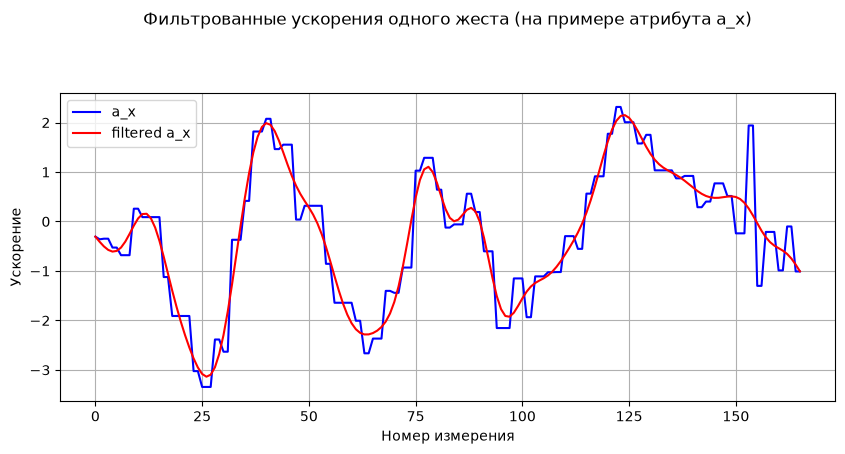

In [92]:
def butterworth_filter_gesture(time_series_matrix):
    wp = 0.17
    ws = 0.30
    gpass = 1
    gstop = 30

    order, cutoff = buttord(wp, ws, gpass, gstop)
    sos = butter(order, cutoff, btype="low", output="sos")
    filtered_matrix = sosfiltfilt(sos, time_series_matrix, axis=0)

    return filtered_matrix


filtered_time_series_matrix_bu = butterworth_filter_gesture(time_series_matrix)
# строим график временных рядов a_x
plt.figure(figsize=(10, 4))

plt.plot(time_series_matrix[:, 0], label="a_x", color="blue")
plt.plot(filtered_time_series_matrix_bu[:, 0], label="filtered a_x", color="red")

plt.title("Фильтрованные ускорения одного жеста (на примере атрибута a_x)\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()

Теперь тоже самое, но реализуем уже медианнй фильтр и построить график для атрибута a_x

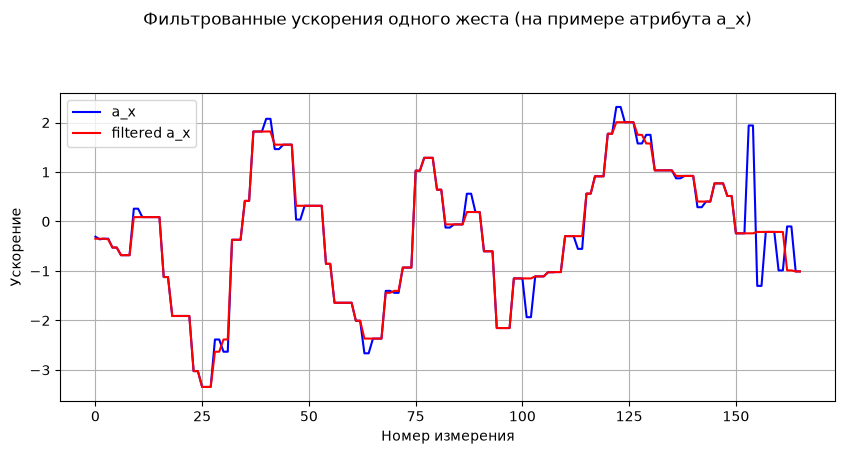

In [93]:
def median_filter_gesture(time_series_matrix, window_size=5):
    return median_filter(
        time_series_matrix,
        size=(window_size, 1)
    )


filtered_time_series_matrix_me = median_filter_gesture(time_series_matrix)
# строим график временных рядов a_x
plt.figure(figsize=(10, 4))

plt.plot(time_series_matrix[:, 0], label="a_x", color="blue")
plt.plot(filtered_time_series_matrix_me[:, 0], label="filtered a_x", color="red")

plt.title("Фильтрованные ускорения одного жеста (на примере атрибута a_x)\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()


Построим графики всех временных рядов одного пользователя

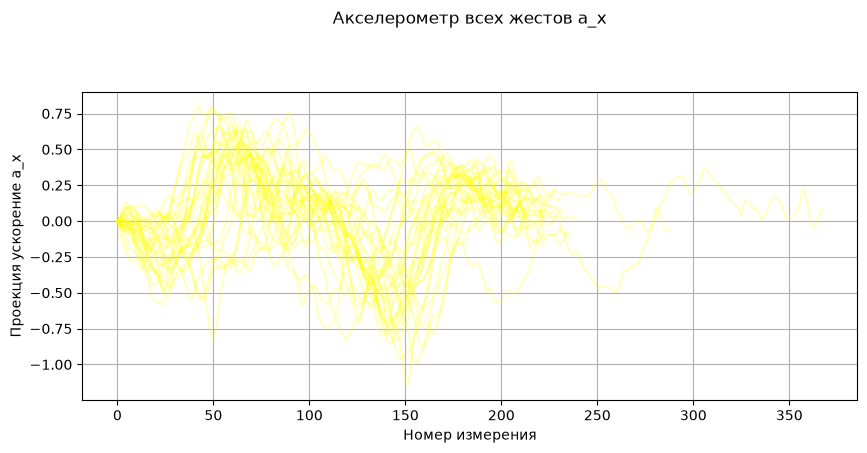

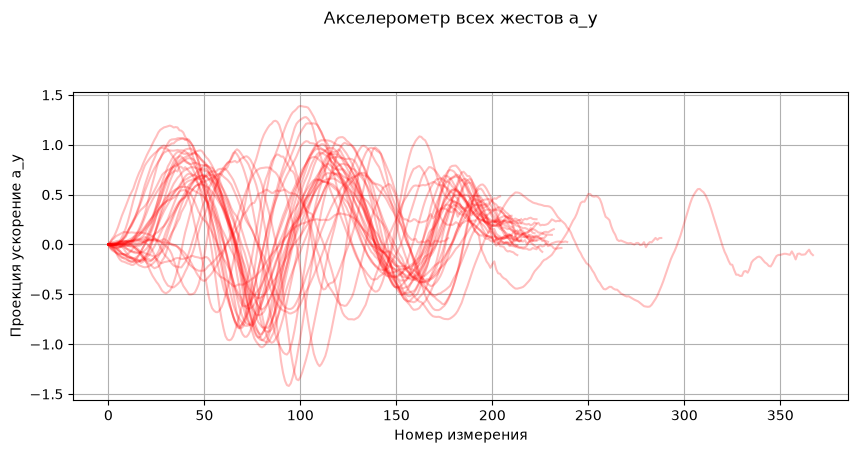

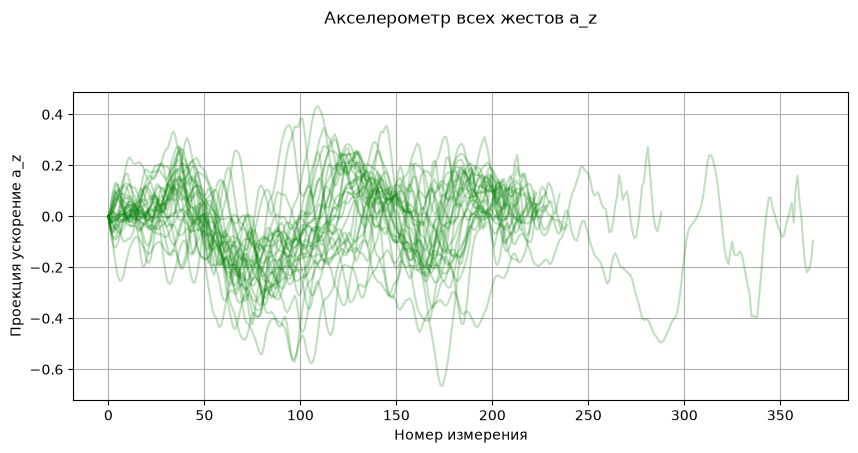

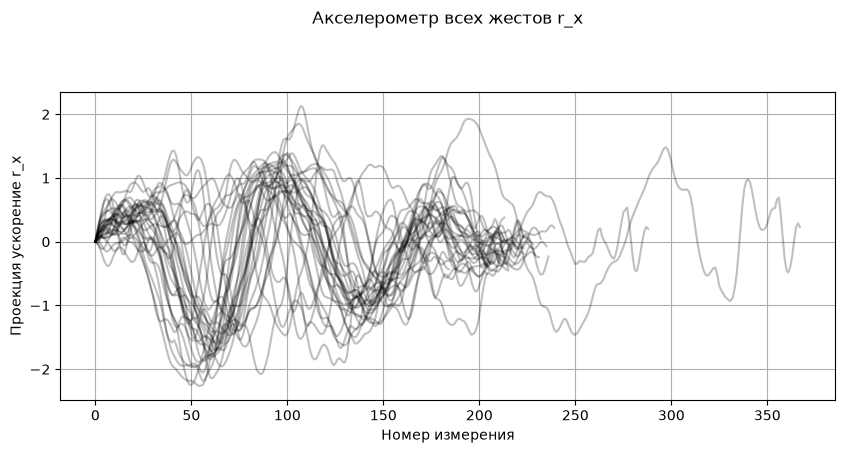

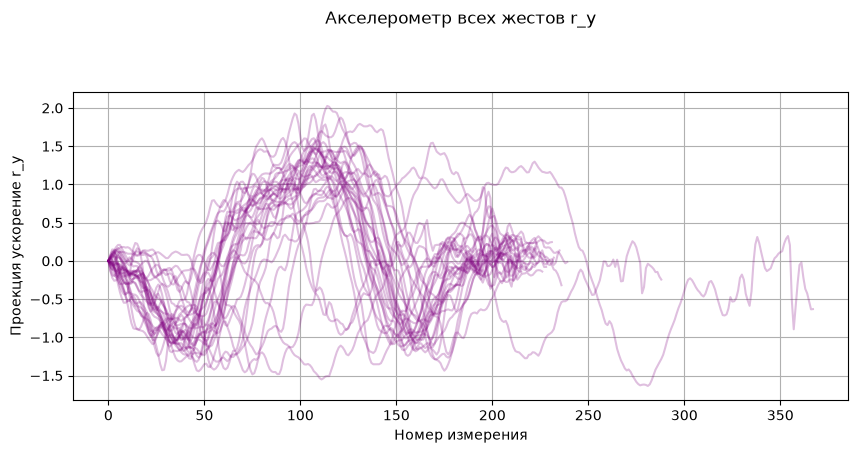

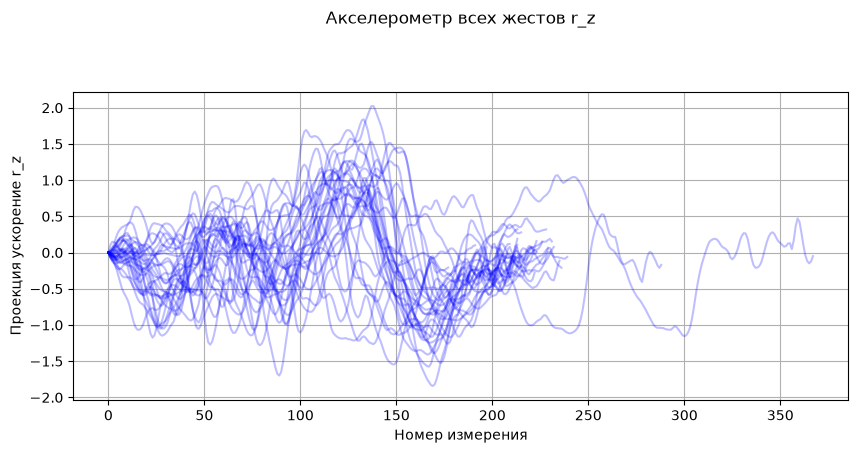

In [94]:
# функция приведения значений угла/угловой скорости r_x к общему типу
def prepare_rotation_angle(time_series_matrix, amount_all_attributes):
    for i in range(amount_all_attributes):
        # приводим r_x к [-180;180]
        if i == 5:
            time_series_matrix[:, i] = ((time_series_matrix[:, i] + 180) % 360) - 180
        # вычитаем начальную ориентацию
        time_series_matrix[:, i] = time_series_matrix[:, i] - time_series_matrix[:, i][0]
    return time_series_matrix

# функция полной фильтрации жеста
def full_filt_gesture(user_folders, train_valid_test, 
                      num_user, num_file, amount_all_attributes, filt):
    
    # парсим атрибуты (временные ряды) из матрицы для i-ого файла
    time_series_matrix = get_gesture(user_folders, train_valid_test, num_user, num_file)

    # приводим углы и вычисляем относительные значени
    time_series_matrix = prepare_rotation_angle(time_series_matrix, amount_all_attributes)
    
    # если фильтрация нужна
    if filt == 1: time_series_matrix = butterworth_filter_gesture(time_series_matrix)
    if filt == 2: time_series_matrix = median_filter_gesture(time_series_matrix)
    return time_series_matrix
    
# функция построения графика одной проекций (атрибута/временного ряда) для всех жестов
def build_one_attribute_plot(user_folders, train_valid_test, num_user, 
                             num_time_series, filt, amount_all_attributes):
    plt.figure(figsize=(10, 4))
    match num_time_series:
        case 0:
            attribute_name = "a_x"
            color_name = "yellow"
        case 1:
            attribute_name = "a_y"
            color_name = "red"
        case 2:
            attribute_name = "a_z"
            color_name = "green"
        case 3:
            attribute_name = "r_x"
            color_name = "black"
        case 4:
            attribute_name = "r_y"
            color_name = "purple"
        case 5:
            attribute_name = "r_z"
            color_name = "blue"

    # считаем кол-во жестов пользователя
    result_path = user_folders[num_user] / "inf" / train_valid_test
    gesture_len = len(list(result_path.iterdir())) - 1
    
    for i in range(gesture_len):
        # парсим и если фильтруем матрицу арибутов
        time_series_matrix = full_filt_gesture(user_folders, train_valid_test, 
                                              num_user, i, amount_all_attributes, filt)
        # отображаем атрибут на графике
        plt.plot(time_series_matrix[:, num_time_series], label=attribute_name, color=color_name, alpha=0.25)

    plt.title("Акселерометр всех жестов " + attribute_name + "\n\n\n")
    plt.xlabel("Номер измерения")
    plt.ylabel("Проекция ускорение " + attribute_name)
    plt.grid(True)
    
    plt.show()

# непосредственно строим все графики
amount_all_attributes = 6
for i in range(amount_all_attributes):
    build_one_attribute_plot(user_folders, train_valid_test="train", 
                             num_user=0, num_time_series=i, filt=0, amount_all_attributes=6)


Применим реализованный фильтр Баттерворта ко всем этим рядам

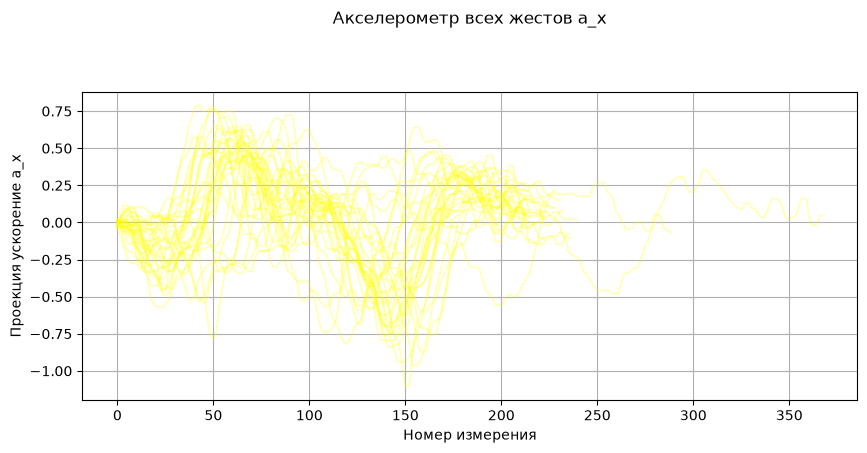

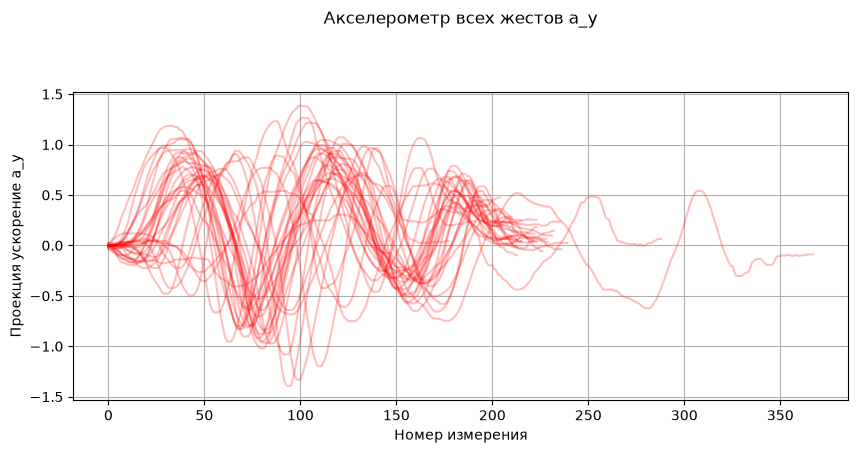

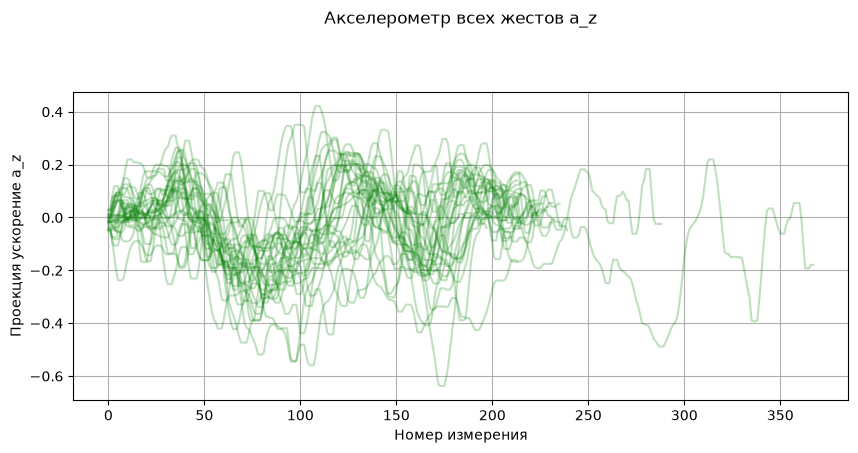

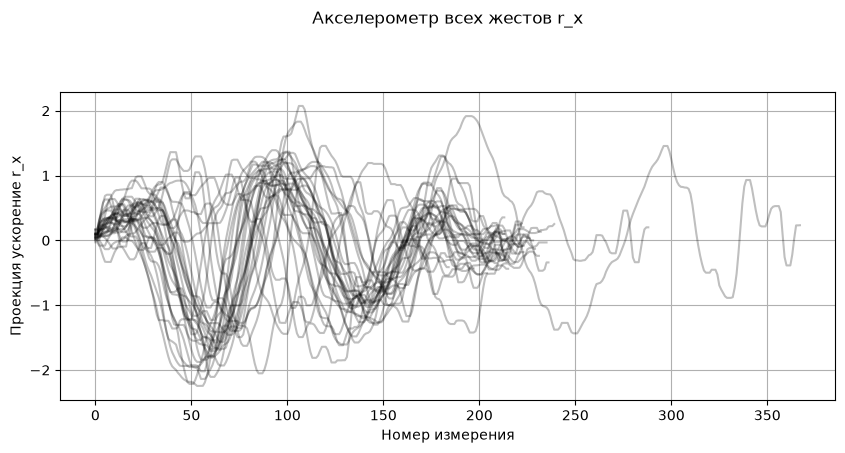

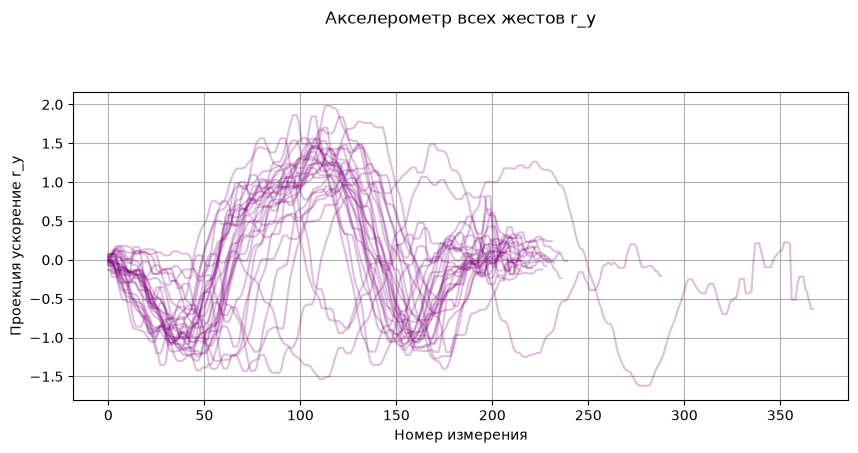

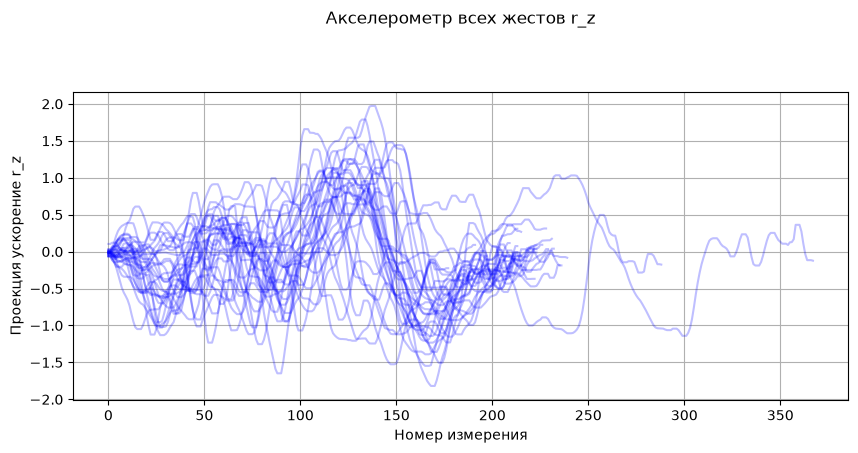

In [95]:
for i in range(amount_all_attributes):
    build_one_attribute_plot(user_folders, train_valid_test="train", 
                             num_user=0, num_time_series=i, filt=2, amount_all_attributes=6)

Создаем таблицу для обучения модели: 30 жестов x 42 признака
42 признака = 6 временных рядов x 7 статистик
ститистика - среднее/медиана/мода/квантиль и д.р. Это то, что используется для описания примерного поведения ряда

In [96]:
def extract_features(processed_gesture):
    mean_values = np.mean(processed_gesture, axis=0)
    std_values = np.std(processed_gesture,axis=0)
    min_values = np.min(processed_gesture,axis=0)
    max_values = np.max(processed_gesture,axis=0)
    median_values = np.median(processed_gesture,axis=0)
    q1_values = np.percentile(processed_gesture, 25,axis=0)
    q3_values = np.percentile(processed_gesture,75,axis=0)

    features = np.concatenate([
        mean_values,
        std_values,
        min_values,
        max_values,
        median_values,
        q1_values,
        q3_values
    ])

    return features


# функция получения всех векторов признаков для пользователя
def get_user_features(user_folders, train_valid_test, num_user, filt):
    # парсим все жесты пользователя
    result_path = user_folders[num_user] / "inf" / train_valid_test
    
    if len(list(result_path.glob("*.txt"))) > 0: 
        gesture_files = list(result_path.glob("*.txt"))
    else: 
        gesture_files = list(result_path.glob("*.json"))

    feature_rows = [] # матрица из строк = векторов признаков
    for i in range(len(gesture_files)):
        # подготавливаем углы и фильтруем
        filtered_gesture = full_filt_gesture(
            user_folders,
            train_valid_test,
            num_user=num_user,
            num_file=i,
            amount_all_attributes=6,
            filt=filt
        )
    
        # получаем 42 признака
        features = extract_features(filtered_gesture)
        feature_rows.append(features)
    return np.array(feature_rows, dtype=float)


# создаем имена признаков = (имя статистики) * (имя атрибута)
attribute_names = ["a_x", "a_y", "a_z", "r_x", "r_y", "r_z"]
statistic_names = ["mean", "std", "min", "max", "median", "q1", "q3"]
feature_names = []

for statistic_name in statistic_names:
    for attribute_name in attribute_names:
        feature_name = (statistic_name + "_" + attribute_name)
        feature_names.append(feature_name)

# получаем матрицу из векторов признаков по всем жестам: (30 жестов)*(42 признака)
feature_rows = []
feature_rows = get_user_features(user_folders, "train", num_user=0, filt=1)
X_train = feature_rows

# названия строк - имена файлов с жестами
gesture_file_names = []
result_path = user_folders[0] / "inf" / "train"
    
if len(list(result_path.glob("*.txt"))) > 0: 
    gesture_files = list(result_path.glob("*.txt"))
else: 
    gesture_files = list(result_path.glob("*.json"))

for i in range(len(gesture_files)):
    gesture_file_names.append(gesture_files[i].name)

# создаем красивую табличку с признаками по жестам
features_table = pd.DataFrame(feature_rows, index=gesture_file_names, columns=feature_names)
features_table.index.name = "gesture_file"

# показываем все признаки по первым 5-ти жестам
pd.set_option("display.max_columns", None)
display(features_table.head())

,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,0.048046,-0.098300,-0.160671,0.177065,-0.152729,0.134537,0.212254,0.321915,0.146778,0.852330,0.802156,0.476886,-0.483940,-0.744792,-0.479933,-1.431319,-1.638483,-1.150414,0.460936,0.555042,0.234471,1.936584,1.240169,1.034811,0.066523,-0.130317,-0.129954,0.289498,-0.187221,0.182580,-0.080264,-0.311460,-0.267200,-0.506380,-0.672748,-0.119476,0.165036,0.169464,-0.051283,0.790495,0.359200,0.474731
s_infinity_11_12_2022_0_17_38.json,-0.013126,0.071688,-0.009538,-0.063003,-0.089543,-0.087275,0.229878,0.344651,0.121864,0.680648,0.777724,0.464242,-0.558256,-0.762916,-0.322339,-1.512126,-1.483500,-1.118043,0.427717,0.614573,0.181481,1.210064,1.507761,0.754490,0.011091,0.041858,0.017269,0.000887,-0.142012,-0.046541,-0.169226,-0.153308,-0.108478,-0.346422,-0.622715,-0.383823,0.167162,0.390517,0.085021,0.332503,0.516842,0.229359
s_infinity_11_12_2022_0_19_18.json,-0.031704,0.099460,0.004693,0.189427,0.070837,-0.266380,0.285817,0.480477,0.144780,0.671749,0.693963,0.607664,-0.560916,-0.968290,-0.311162,-1.199148,-0.871620,-1.242309,0.576649,0.894046,0.376240,1.280998,1.597952,0.896984,0.006035,0.037969,0.011301,0.333058,-0.046828,-0.265519,-0.263119,-0.193805,-0.109472,-0.195621,-0.546329,-0.794426,0.173590,0.513250,0.093747,0.754797,0.385285,0.163524
s_infinity_11_12_2022_0_19_26.json,0.045019,0.359948,0.063710,-0.229757,0.101238,-0.308830,0.327208,0.486934,0.142683,0.665219,0.693526,0.600765,-0.757353,-0.687031,-0.203390,-1.322708,-0.952358,-1.197047,0.559792,1.237774,0.355800,1.029952,1.467963,1.011608,0.085987,0.331813,0.072592,-0.197680,0.030591,-0.366270,-0.175454,0.024161,-0.071868,-0.775553,-0.501731,-0.770330,0.322700,0.783548,0.174670,0.315420,0.582378,-0.019418
s_infinity_11_12_2022_0_20_36.json,-0.054232,0.079346,-0.087701,0.275105,0.038727,-0.150549,0.370001,0.570263,0.166778,0.843010,0.907970,0.605214,-1.060938,-1.420539,-0.532165,-1.666934,-1.305360,-1.120122,0.725033,1.019486,0.176145,1.837795,1.816193,1.220070,-0.019163,0.033627,-0.050386,0.367470,-0.049171,-0.145322,-0.268000,-0.316669,-0.188594,-0.312912,-0.623633,-0.664069,0.123526,0.558012,0.041374,0.925354,0.596268,0.193489


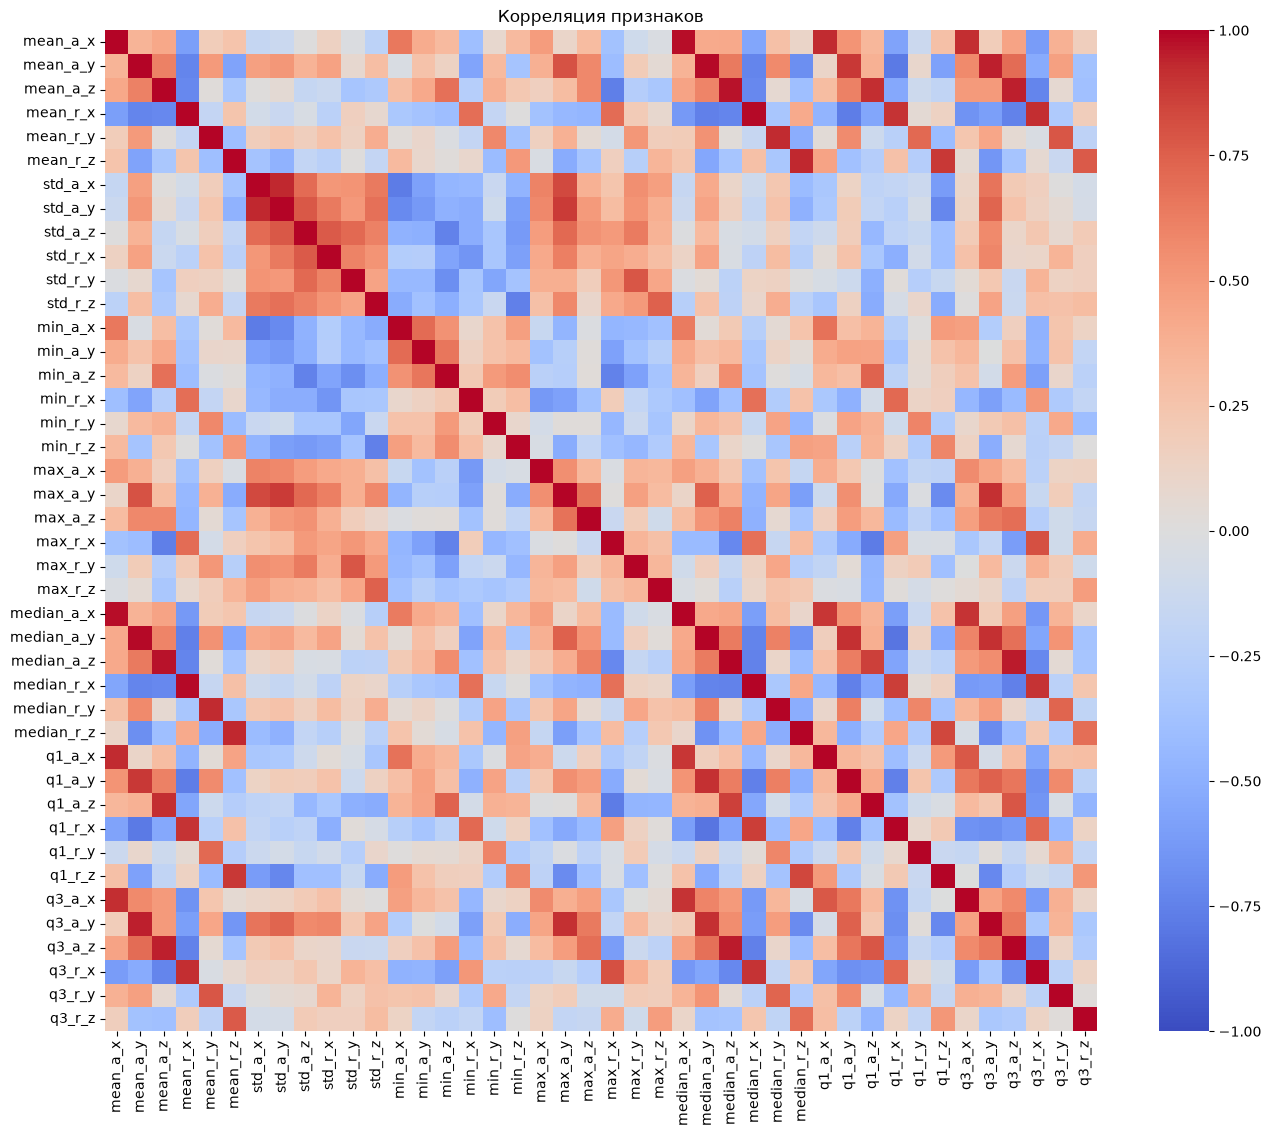

mean_a_y    median_a_y    0.989396
mean_r_x    median_r_x    0.986200
mean_a_x    median_a_x    0.981965
mean_a_z    median_a_z    0.972966
median_a_z  q3_a_z        0.954783
mean_a_z    q3_a_z        0.950048
mean_a_y    q3_a_y        0.946173
mean_r_z    median_r_z    0.937478
std_a_x     std_a_y       0.934636
mean_a_x    q1_a_x        0.928869
mean_r_y    median_r_y    0.926796
mean_a_x    q3_a_x        0.920971
mean_r_x    q3_r_x        0.917553
mean_a_z    q1_a_z        0.915005
max_a_y     q3_a_y        0.912457
median_a_y  q3_a_y        0.910397
            q1_a_y        0.910160
mean_r_x    q1_r_x        0.905115
median_a_x  q3_a_x        0.904286
median_r_x  q3_r_x        0.902118
dtype: float64

In [97]:
# строим матрицу корреляций
correlation = features_table.corr()

plt.figure(figsize=(16, 13))

sns.heatmap(correlation, cmap="coolwarm", center=0, vmin=-1, vmax=1)

plt.title("Корреляция признаков")
plt.show()

upper_triangle = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))

strong_pairs = upper_triangle.stack()
strong_pairs = strong_pairs[strong_pairs.abs() > 0.9]

display(strong_pairs.sort_values(key=abs, ascending=False))

                                    Стандартизация
Стандартизация показывает на сколько стандартных отклонений значение отклонилось от среднего. Она нужна для того, чтобы сделать данные независимыми от их единиц измерения, т.е. относительными друг от друга





In [98]:
# создаем объект scaler
scaler = StandardScaler()
# вычисляем для каждого столбца (признака) среднее и стандартное отклонение
scaler.fit(X_train)
# стандартизируем признаки 
X_train_scaled = scaler.transform(X_train)

# выводим стандартизированные признаки для первых 5-ти жестов
scaled_features_table = pd.DataFrame(
    X_train_scaled,
    index=features_table.index,
    columns=features_table.columns
)
print('\n\n', "                                              Б Ы Л О")
display(features_table.head())
print('\n\n',"                                              С Т А Л О")
display(scaled_features_table.head())



                                               Б Ы Л О


,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,0.048046,-0.098300,-0.160671,0.177065,-0.152729,0.134537,0.212254,0.321915,0.146778,0.852330,0.802156,0.476886,-0.483940,-0.744792,-0.479933,-1.431319,-1.638483,-1.150414,0.460936,0.555042,0.234471,1.936584,1.240169,1.034811,0.066523,-0.130317,-0.129954,0.289498,-0.187221,0.182580,-0.080264,-0.311460,-0.267200,-0.506380,-0.672748,-0.119476,0.165036,0.169464,-0.051283,0.790495,0.359200,0.474731
s_infinity_11_12_2022_0_17_38.json,-0.013126,0.071688,-0.009538,-0.063003,-0.089543,-0.087275,0.229878,0.344651,0.121864,0.680648,0.777724,0.464242,-0.558256,-0.762916,-0.322339,-1.512126,-1.483500,-1.118043,0.427717,0.614573,0.181481,1.210064,1.507761,0.754490,0.011091,0.041858,0.017269,0.000887,-0.142012,-0.046541,-0.169226,-0.153308,-0.108478,-0.346422,-0.622715,-0.383823,0.167162,0.390517,0.085021,0.332503,0.516842,0.229359
s_infinity_11_12_2022_0_19_18.json,-0.031704,0.099460,0.004693,0.189427,0.070837,-0.266380,0.285817,0.480477,0.144780,0.671749,0.693963,0.607664,-0.560916,-0.968290,-0.311162,-1.199148,-0.871620,-1.242309,0.576649,0.894046,0.376240,1.280998,1.597952,0.896984,0.006035,0.037969,0.011301,0.333058,-0.046828,-0.265519,-0.263119,-0.193805,-0.109472,-0.195621,-0.546329,-0.794426,0.173590,0.513250,0.093747,0.754797,0.385285,0.163524
s_infinity_11_12_2022_0_19_26.json,0.045019,0.359948,0.063710,-0.229757,0.101238,-0.308830,0.327208,0.486934,0.142683,0.665219,0.693526,0.600765,-0.757353,-0.687031,-0.203390,-1.322708,-0.952358,-1.197047,0.559792,1.237774,0.355800,1.029952,1.467963,1.011608,0.085987,0.331813,0.072592,-0.197680,0.030591,-0.366270,-0.175454,0.024161,-0.071868,-0.775553,-0.501731,-0.770330,0.322700,0.783548,0.174670,0.315420,0.582378,-0.019418
s_infinity_11_12_2022_0_20_36.json,-0.054232,0.079346,-0.087701,0.275105,0.038727,-0.150549,0.370001,0.570263,0.166778,0.843010,0.907970,0.605214,-1.060938,-1.420539,-0.532165,-1.666934,-1.305360,-1.120122,0.725033,1.019486,0.176145,1.837795,1.816193,1.220070,-0.019163,0.033627,-0.050386,0.367470,-0.049171,-0.145322,-0.268000,-0.316669,-0.188594,-0.312912,-0.623633,-0.664069,0.123526,0.558012,0.041374,0.925354,0.596268,0.193489




                                               С Т А Л О


,mean_a_x,mean_a_y,mean_a_z,mean_r_x,mean_r_y,mean_r_z,std_a_x,std_a_y,std_a_z,std_r_x,std_r_y,std_r_z,min_a_x,min_a_y,min_a_z,min_r_x,min_r_y,min_r_z,max_a_x,max_a_y,max_a_z,max_r_x,max_r_y,max_r_z,median_a_x,median_a_y,median_a_z,median_r_x,median_r_y,median_r_z,q1_a_x,q1_a_y,q1_a_z,q1_r_x,q1_r_y,q1_r_z,q3_a_x,q3_a_y,q3_a_z,q3_r_x,q3_r_y,q3_r_z
gesture_file,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
s_infinity_11_12_2022_0_17_19.json,0.259995,-2.177855,-2.288389,1.341411,-1.627632,1.628683,-2.023615,-1.687069,0.342257,1.302376,0.848990,-0.795711,1.226566,0.611434,-1.298468,0.908268,-2.383747,-0.020221,-1.148297,-1.747464,0.023326,2.381089,-0.821362,-0.602202,-0.057402,-2.121663,-2.348583,1.357540,-1.626259,2.087411,0.944112,-1.898410,-1.911519,0.491453,-0.999400,1.862702,-0.476568,-2.133343,-2.157185,1.703548,-1.069619,1.565451
s_infinity_11_12_2022_0_17_38.json,-0.440718,-0.821671,0.256689,0.188198,-1.076561,0.021488,-1.583904,-1.369481,-0.584682,-0.671841,0.507328,-0.909367,0.764942,0.522375,0.192931,0.632145,-1.554949,0.084261,-1.453404,-1.454203,-0.624238,-0.030695,0.310400,-1.517563,-0.635753,-0.823112,0.294688,0.053983,-1.248472,0.585381,-0.079561,-0.424855,0.305590,1.069748,-0.535756,0.447004,-0.454798,-0.852001,0.136090,-0.550909,-0.315228,0.060626
s_infinity_11_12_2022_0_19_18.json,-0.653533,-0.600103,0.496346,1.400794,0.322190,-1.276257,-0.188215,0.527797,0.267918,-0.774175,-0.664029,0.379880,0.748418,-0.486796,0.298706,1.701612,1.717175,-0.316827,-0.085512,-0.077456,1.755824,0.204781,0.691859,-1.052264,-0.688507,-0.852448,0.187534,1.554284,-0.453072,-0.850164,-1.159960,-0.802176,0.291706,1.614935,0.172094,-1.751960,-0.388970,-0.140579,0.282886,1.527829,-0.944792,-0.343131
s_infinity_11_12_2022_0_19_26.json,0.225315,1.478106,1.490186,-0.612839,0.587327,-1.583843,0.844485,0.617996,0.189906,-0.849270,-0.670145,0.317862,-0.471788,0.895264,1.318614,1.279401,1.285415,-0.170738,-0.240338,1.615822,1.506033,-0.628603,0.142075,-0.677971,0.145675,1.363735,1.287962,-0.842869,0.193879,-1.510652,-0.151219,1.228689,0.816969,-0.481686,0.585373,-1.622916,1.137876,1.426216,1.644389,-0.635000,-0.001607,-1.465087
s_infinity_11_12_2022_0_20_36.json,-0.911587,-0.760576,-1.059574,1.812363,0.042142,-0.436973,1.912173,1.781975,1.086374,1.195203,2.328737,0.357861,-2.357559,-2.709067,-1.792765,0.103153,-0.602315,0.077550,1.277341,0.540490,-0.689453,2.053147,1.614895,0.002742,-0.951414,-0.885195,-0.919999,1.709709,-0.472651,-0.062191,-1.216133,-1.946944,-0.813511,1.190896,-0.544259,-1.053840,-0.901616,0.118887,-0.598259,2.367388,0.064867,-0.159359





### Обучаем модель для конкретного пользователя на основе одноклассового SVM

<mark>Мы создаем объект модели "model", используя следующие параметры:<mark>
1. **kernel="rbf"**
kernel, определяет, по какой формуле модель измеряет сходство двух векторов признаков.
Существуют разные способы: линейное ядро (не может построить изогнутую гиперплоскость), полиномиальное (тяжело подобрать нужную степень, нужно соблюдать баланс гибкость-чувствительность), радиально-базисное ядро (наш вариант оценивает похожесть по расстоянию между жестами и создаёт мягкие области влияния около опорных векторов)

$$
K(x_i, x) = e^{-\gamma \left\|x - x_i\right\|^2}
$$

2. **gamma="scale"**
Гамма из формулы для ядра определяется автоматически. Если гамма будет маленькой, то границы могут быть разрывными (появляются островки около отдельных концов опорных векторов). Если гамма большая, то граница непрерывна и все объекты лежат внутри этой границы. Граница в таком случае выглядит примерно как натянутая на кучу вбитых гвоздей резинка. Чем больше гамма тем больше риск, что в область могут попасть объекты, не принадлежащие этому классу. Чем гамма меньше, тем больше риск, что в область не попадут объекты, принадлежащие этому классу. 
То есть гамма задает что-то вроде эпсилон окрестности вокруг каждого конца опорного вектора, но эта епсилон окрестность имеет внутри радиальную структуру похожести (то есть чем больше расстояние до конца опорного вектора, тем похожесть меньше)

3. **u=0.1** 
Разрешает модели считать небольшую часть обучающих жестов необычными. При 30 жестах это приблизительно несколько объектов (где-то 0.1 * 30 = 3)

<mark>Применяем model.fit(X_train_scaled)<mark>

Во время .fit() модель:
1. выбирает опорные векторы;
2. вычисляет их веса ($ \alpha_i $);
3. вычисляет порог ($ \rho $);
4. строит границу, то есть функцию определения того, насколько объект далек от границы:

$$
f(x) =
\sum_{i=1}^{m}
\alpha_i
\exp\left(
-\gamma \left\|x - x_i\right\|^2
\right)
-\rho
$$

- если f(x) < 0, то есть сумма влияния всех опорных векторов на эту точку меньше порогового значения ро, то объект x считается вне построенной границы
- если f(x) > 0, то объект внутри границы
- если f(x) = 0, то объект на границе

In [107]:
model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.1

model.fit(X_train_scaled)




### Обучаем модель для конкретного пользователя на основе одноклассового SVM

<mark>Мы создаем объект модели "model", используя следующие параметры:<mark>
1. **kernel="rbf"**
kernel, определяет, по какой формуле модель измеряет сходство двух векторов признаков.
Существуют разные способы: линейное ядро (не может построить изогнутую гиперплоскость), полиномиальное (тяжело подобрать нужную степень, нужно соблюдать баланс гибкость-чувствительность), радиально-базисное ядро (наш вариант оценивает похожесть по расстоянию между жестами и создаёт мягкие области влияния около опорных векторов)

$$
K(x_i, x) = e^{-\gamma \left\|x - x_i\right\|^2}
$$

2. **gamma="scale"**
Гамма из формулы для ядра определяется автоматически. Если гамма будет маленькой, то границы могут быть разрывными (появляются островки около отдельных концов опорных векторов). Если гамма большая, то граница непрерывна и все объекты лежат внутри этой границы. Граница в таком случае выглядит примерно как натянутая на кучу вбитых гвоздей резинка. Чем больше гамма тем больше риск, что в область могут попасть объекты, не принадлежащие этому классу. Чем гамма меньше, тем больше риск, что в область не попадут объекты, принадлежащие этому классу. 
То есть гамма задает что-то вроде эпсилон окрестности вокруг каждого конца опорного вектора, но эта епсилон окрестность имеет внутри радиальную структуру похожести (то есть чем больше расстояние до конца опорного вектора, тем похожесть меньше)

3. **u=0.1** 
Разрешает модели считать небольшую часть обучающих жестов необычными. При 30 жестах это приблизительно несколько объектов (где-то 0.1 * 30 = 3)

<mark>Применяем model.fit(X_train_scaled)<mark>

Во время .fit() модель:
1. выбирает опорные векторы;
2. вычисляет их веса ($ \alpha_i $);
3. вычисляет порог ($ \rho $);
4. строит границу, то есть функцию определения того, насколько объект далек от границы:

$$
f(x) =
\sum_{i=1}^{m}
\alpha_i
\exp\left(
-\gamma \left\|x - x_i\right\|^2
\right)
-\rho
$$

- если f(x) < 0, то есть сумма влияния всех опорных векторов на эту точку меньше порогового значения ро, то объект x считается вне построенной границы
- если f(x) > 0, то объект внутри границы
- если f(x) = 0, то объект на границе

In [ ]:
Строим матрицу корреляций

In [109]:
#X_validation_scaled = scaler.transform(X_validation)
#ОШИБКА_____________________________________








# Предсказания модели: 1 или -1
svm_predictions = model.predict(X_validation_scaled)

# Преобразуем: 1 остаётся 1, а -1 превращается в 0
y_pred = (svm_predictions == 1).astype(int)

# Строим матрицу ошибок
cm = confusion_matrix(
    y_validation,
    y_pred,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Посторонний", "Владелец"]
)

display.plot(cmap="Blues")
plt.title("Матрица ошибок")
plt.show()

NameError: name 'X_validation_scaled' is not defined

In [ ]:
# функция загрузки фалидационных данных
def get_all_valid_test_features(user_folders, valid_test, filt):
    print("Загрузка валидационных данных в память...")
    all_valid_test_features = []
    for i in range(len(user_folders)):
        all_valid_test_features.append(get_user_features(user_folders, valid_test, num_user=i, filt=filt))
    return all_valid_test_features


# функция подсчета roc auc для одного пользователя
def get_roc_auc_for_one(user_folders, owner_user, X_train_scaled, scaler, all_valid_test_features, filt, model_id):
    # создаем объект model
    # через одноклассовую SVM
    if model_id == 1:
        model = OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.1
        )

    # через изоляционный лес
    if model_id == 2:
        model = IsolationForest(
            n_estimators=200,
            contamination=0.1,
            random_state=42
        )
    
    # обучаем модеь на стандартизированных данных
    model.fit(X_train_scaled)

    # получаем векторы признаков владельца телефона
    X_owner = all_valid_test_features[owner_user]
    
    # получаем векторы признаков не-владельцев этого телефона
    impostor_features = [all_valid_test_features[i] for i in range(len(all_valid_test_features)) if i != owner_user]
    X_impostors = np.vstack(impostor_features)# кладем векторы друг на друга
    
    print(X_impostors.shape)
    print(X_owner.shape)
    
    # кладем таблички друг на друга
    X_valid_test = np.vstack([
        X_owner,
        X_impostors
    ])
    
    # получаем один вектор вида 111..1000...0 склеивая два вектора
    y_valid_test = np.concatenate([
        # создаем массив единичек
        np.ones(
            len(X_owner),
            dtype=int
        ),
        # создаем массив ноликов
        np.zeros(
            len(X_impostor),
            dtype=int
        )
    ])
    
    # проводим стандартизацию для валидационной выборки
    X_scaled = scaler.transform(X_valid_test)
    
    # считаем значения функции, кторая показывает насколько объект далек от границы, для новых данных
    scores = model.decision_function(X_scaled)
    
    # получаем roc auc, которая сравнивает реальные данные и значения функции дальности до границы
    roc_auc = roc_auc_score(y_valid_test, scores)
    print("ROC AUC for owner =", owner_user, ":", roc_auc)

    return roc_auc, X_scaled, y_valid_test

def evaluate_one_user(
    user_folders,
    all_valid_test_features,
    owner_user,
    mean_fpr_grid,
    mean_recall_grid,
    filt,
    model_id
):

    # получаем тренировочные жесты владельца
    X_train = get_user_features(
        user_folders,
        "train",
        num_user=owner_user,
        filt=filt
    )

    # cтандартизируем тренировочные признаки
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    # обучаем отдельную модель владельца
    # через одноклассовую SVM
    if model_id == 1:
        model = OneClassSVM(
            kernel="rbf",
            gamma="scale",
            nu=0.1
        )

    # через изоляционный лес
    if model_id == 2:
        model = IsolationForest(
            n_estimators=200,
            contamination=0.1,
            random_state=42
        )
    model.fit(X_train_scaled)

    # получаем валидационныую выборку владельца
    X_owner = all_valid_test_features[owner_user]

    # собираем валидационную выборку посторонних (мошенников)
    impostor_matrices = []
    for user_index in range(len(user_folders)):
        if user_index == owner_user:
            continue
        impostor_matrices.append(all_valid_test_features[user_index])
    # кладем вектора признаков друг на друга (собираем их в матрицу)
    X_impostors = np.vstack(impostor_matrices)

    # cобираем общую валидационныую выборку
    X_valid_test = np.vstack([
        X_owner,
        X_impostors
    ])

    # получаем размеченный столбец для X_validation для того чтобы проверить метрики (0 - мошенник, 1 - владелец)
    y_valid_test = np.concatenate([
        np.ones(len(X_owner), dtype=int),
        np.zeros(len(X_impostors), dtype=int)
    ])

    # стандартизируем валидационную выборку (scaler обучен на тренировочной)
    X_scaled = scaler.transform(X_valid_test)

    # получаем оценки модели
    scores = model.decision_function(X_scaled)

    # ROC AUC и ROC-кривая
    roc_auc = roc_auc_score(y_valid_test, scores)
    fpr, tpr, roc_thresholds = roc_curve(y_valid_test, scores)
    far_values = fpr
    frr_values = 1 - tpr

    # находим EER и порог EER
    eer_index = np.argmin(np.abs(far_values - frr_values))
    eer_threshold = roc_thresholds[eer_index]
    eer = (far_values[eer_index] + frr_values[eer_index]) / 2

    # получаем итоговые предсказания
    y_pred = (scores >= eer_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    far = fp / (fp + tn)
    frr = fn / (fn + tp)


    # PR AUC и PR-кривая
    precision, recall, pr_thresholds = (
        precision_recall_curve(
            y_valid_test,
            scores
        )
    )

    pr_auc = average_precision_score(y_valid_test, scores)

    # результаты текущего пользователя
    metrics = {
        "user": owner_user,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "FAR": far,
        "FRR": frr,
        "EER": eer,
        "threshold": eer_threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    # интерполируем ROC-кривую
    interpolated_tpr = np.interp(mean_fpr_grid, fpr, tpr)
    interpolated_tpr[0] = 0

    # интерполируем PR-кривую
    # recall возвращается в убывающем порядке,
    # поэтому разворачиваем массивы.
    interpolated_precision = np.interp(
        mean_recall_grid,
        recall[::-1],
        precision[::-1]
    )

    curve_data = {
        "tpr": interpolated_tpr,
        "precision": interpolated_precision,
        "positive_rate": np.mean(y_valid_test)
    }

    return metrics, curve_data


def show_metrics_summary(metrics_table):

    print("Метрики всех пользователей:")
    display(metrics_table.round(4))

    metric_names = [
        "ROC_AUC",
        "PR_AUC",
        "FAR",
        "FRR",
        "EER"
    ]

    summary_table = metrics_table[metric_names].agg(["mean", "std", "median", "min", "max"]).T

    print("\nСводные показатели:")
    display(summary_table.round(4))

    return summary_table


def plot_mean_curves(curve_data_list, metrics_table, mean_fpr_grid, mean_recall_grid):

    # собираем данные всех ROC-кривых
    tpr_array = np.array([
        curve_data["tpr"]
        for curve_data in curve_data_list
    ])

    mean_tpr = np.mean(tpr_array, axis=0)
    std_tpr = np.std(tpr_array, axis=0)
    mean_tpr[-1] = 1

    # собираем данные всех PR-кривых
    precision_array = np.array([
        curve_data["precision"]
        for curve_data in curve_data_list
    ])

    mean_precision = np.mean(precision_array, axis=0)
    std_precision = np.std(precision_array, axis=0)

    mean_positive_rate = np.mean([
        curve_data["positive_rate"]
        for curve_data in curve_data_list
    ])

    # получаем средние AUC
    mean_roc_auc = metrics_table["ROC_AUC"].mean()
    mean_pr_auc = metrics_table["PR_AUC"].mean()

    # cоздаём два графика
    figure, axes = plt.subplots(1, 2, figsize=(14, 5))

    # средняя ROC-кривая
    axes[0].plot(
        mean_fpr_grid,
        mean_tpr,
        color="blue",
        label=(
            "Средняя ROC-кривая\n"
            f"Средний ROC AUC = "
            f"{mean_roc_auc:.3f}"
        )
    )

    axes[0].fill_between(
        mean_fpr_grid,
        np.maximum(mean_tpr - std_tpr,0),
        np.minimum(mean_tpr + std_tpr, 1),
        color="blue",
        alpha=0.2,
        label="± стандартное отклонение"
    )

    axes[0].plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Случайная модель"
    )

    axes[0].set_xlabel("FAR / False Positive Rate")
    axes[0].set_ylabel("TPR / Recall")
    axes[0].set_title("Средняя ROC-кривая")
    axes[0].grid(True)
    axes[0].legend()

    # средняя PR-кривая
    axes[1].plot(
        mean_recall_grid,
        mean_precision,
        color="darkorange",
        label=(
            "Средняя PR-кривая\n"
            f"Средний PR AUC = "
            f"{mean_pr_auc:.3f}"
        )
    )

    axes[1].fill_between(
        mean_recall_grid,
        np.maximum(mean_precision - std_precision, 0),
        np.minimum(mean_precision + std_precision, 1),
        color="darkorange",
        alpha=0.2,
        label="± стандартное отклонение"
    )

    axes[1].axhline(
        mean_positive_rate,
        linestyle="--",
        color="gray",
        label=(
            "Случайный уровень = "
            f"{mean_positive_rate:.3f}"
        )
    )

    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_title("Средняя Precision–Recall кривая")
    axes[1].grid(True)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def run_all_users_analysis(user_folders, valid_test, filt, model_id):

    # сетки для усреднения кривых
    mean_fpr_grid = np.linspace(0, 1, 201)
    mean_recall_grid = np.linspace(0, 1, 201)

    # один раз читаем validation
    all_valid_test_features = get_all_valid_test_features(user_folders, valid_test, filt)

    metrics_rows = []
    curve_data_list = []
    
    # обучаем и проверяем модель каждого владельца
    for owner_user in range(len(user_folders)):

        metrics, curve_data = evaluate_one_user(
            user_folders=user_folders,
            all_valid_test_features=(all_valid_test_features),
            owner_user=owner_user,
            mean_fpr_grid=mean_fpr_grid,
            mean_recall_grid=(mean_recall_grid),
            filt=filt,
            model_id=model_id
        )

        metrics_rows.append(metrics)
        curve_data_list.append(curve_data)

    # создаём и выводим таблицу
    metrics_table = pd.DataFrame(metrics_rows)
    summary_table = show_metrics_summary(metrics_table)

    # строим средние кривые
    plot_mean_curves(
        curve_data_list=curve_data_list,
        metrics_table=metrics_table,
        mean_fpr_grid=mean_fpr_grid,
        mean_recall_grid=mean_recall_grid
    )

    return metrics_table, summary_table

# для валидационной выборки
metrics_table, summary_table = (run_all_users_analysis(user_folders, "valid", filt=0, model_id=2))
metrics_table, summary_table = (run_all_users_analysis(user_folders, "valid", filt=1, model_id=2))
metrics_table, summary_table = (run_all_users_analysis(user_folders, "valid", filt=2

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,0.8750,0.5351,0.2429,0.2,0.2214,0.0160,106,34,2,8
1,1,0.9136,0.6659,0.1143,0.1,0.1071,-0.0215,124,16,1,9
2,2,0.9971,0.9714,0.0286,0.0,0.0143,-0.0134,136,4,0,10
3,3,0.9593,0.6371,0.0714,0.1,0.0857,0.0068,130,10,1,9
4,4,0.9779,0.8280,0.1214,0.1,0.1107,0.0219,123,17,1,9
5,5,0.9943,0.9556,0.0571,0.1,0.0786,-0.0330,132,8,1,9
6,6,0.9993,0.9909,0.0071,0.0,0.0036,0.0017,139,1,0,10
7,7,1.0000,1.0000,0.0000,0.0,0.0000,-0.0302,140,0,0,10
8,8,0.9136,0.5247,0.2071,0.2,0.2036,-0.0394,111,29,2,8
9,9,1.0000,1.0000,0.0000,0.0,0.0000,-0.0117,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9649,0.0392,0.9779,0.8750,1.0000
PR_AUC,0.8205,0.1648,0.8433,0.5247,1.0000
FAR,0.0862,0.0713,0.0786,0.0000,0.2429
FRR,0.0800,0.0676,0.1000,0.0000,0.2000
EER,0.0831,0.0685,0.0893,0.0000,0.2214


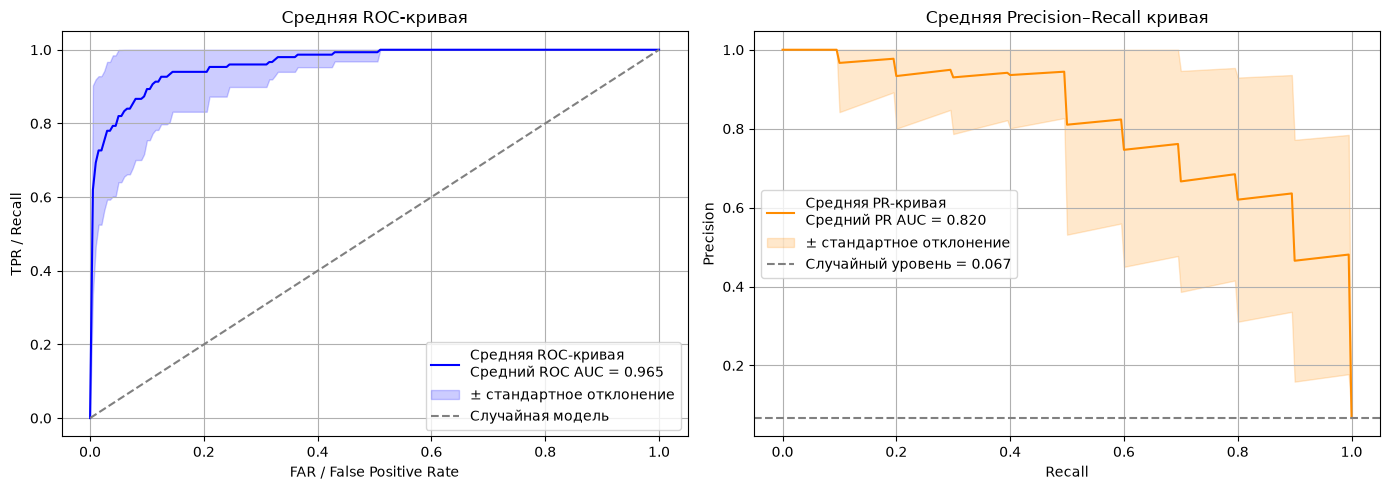

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,0.8850,0.5693,0.2429,0.2,0.2214,0.0180,106,34,2,8
1,1,0.9214,0.6793,0.1071,0.1,0.1036,-0.0233,125,15,1,9
2,2,0.9964,0.9667,0.0357,0.0,0.0179,-0.0145,135,5,0,10
3,3,0.9536,0.6110,0.0857,0.1,0.0929,0.0008,128,12,1,9
4,4,0.9757,0.8023,0.1143,0.1,0.1071,0.0276,124,16,1,9
5,5,1.0000,1.0000,0.0000,0.0,0.0000,-0.0288,140,0,0,10
6,6,0.9993,0.9909,0.0071,0.0,0.0036,-0.0097,139,1,0,10
7,7,1.0000,1.0000,0.0000,0.0,0.0000,-0.0341,140,0,0,10
8,8,0.9271,0.5560,0.1071,0.1,0.1036,-0.0233,125,15,1,9
9,9,1.0000,1.0000,0.0000,0.0,0.0000,-0.0447,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9685,0.0364,0.9879,0.885,1.0000
PR_AUC,0.8324,0.1669,0.8920,0.556,1.0000
FAR,0.0671,0.0648,0.0714,0.000,0.2429
FRR,0.0667,0.0617,0.1000,0.000,0.2000
EER,0.0669,0.0624,0.0857,0.000,0.2214


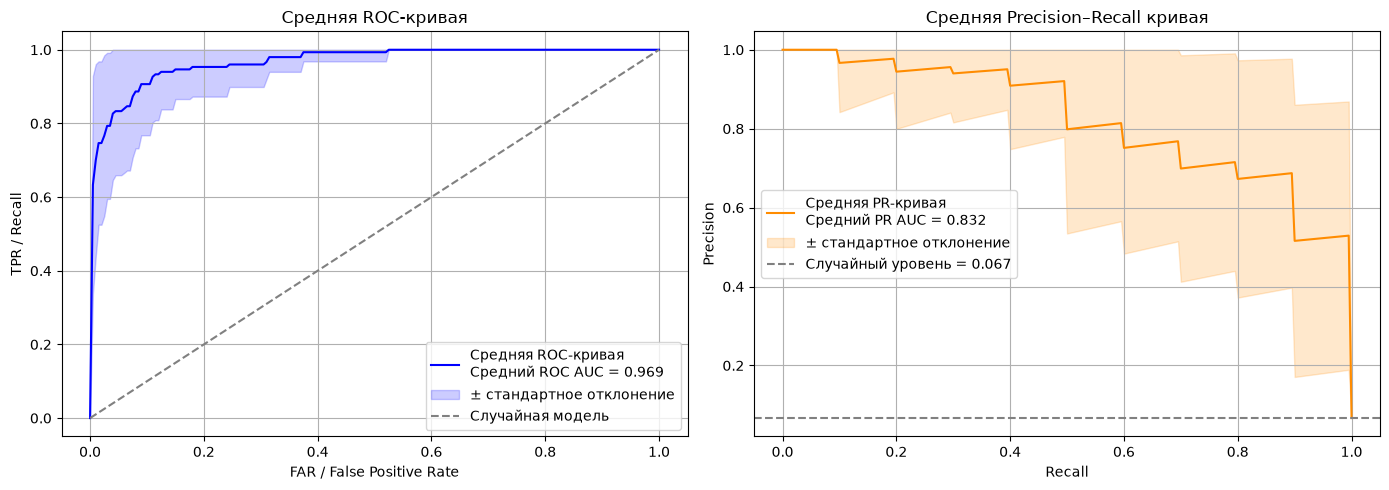

Загрузка валидационных данных в память...
Метрики всех пользователей:


,user,ROC_AUC,PR_AUC,FAR,FRR,EER,threshold,TN,FP,FN,TP
0,0,0.8914,0.6005,0.2214,0.2,0.2107,0.0212,109,31,2,8
1,1,0.9200,0.6724,0.1143,0.1,0.1071,-0.0246,124,16,1,9
2,2,0.9964,0.9667,0.0357,0.0,0.0179,-0.0210,135,5,0,10
3,3,0.9579,0.6131,0.0714,0.1,0.0857,0.0070,130,10,1,9
4,4,0.9793,0.8356,0.1071,0.1,0.1036,0.0216,125,15,1,9
5,5,0.9979,0.9733,0.0143,0.0,0.0071,-0.0259,138,2,0,10
6,6,0.9993,0.9909,0.0071,0.0,0.0036,0.0035,139,1,0,10
7,7,1.0000,1.0000,0.0000,0.0,0.0000,-0.0265,140,0,0,10
8,8,0.9236,0.5376,0.1500,0.2,0.1750,-0.0320,119,21,2,8
9,9,1.0000,1.0000,0.0000,0.0,0.0000,-0.0231,140,0,0,10



Сводные показатели:


,mean,std,median,min,max
ROC_AUC,0.9678,0.0352,0.9793,0.8914,1.0000
PR_AUC,0.8272,0.1599,0.8356,0.5376,1.0000
FAR,0.0719,0.0626,0.0714,0.0000,0.2214
FRR,0.0733,0.0704,0.1000,0.0000,0.2000
EER,0.0726,0.0655,0.0857,0.0000,0.2107


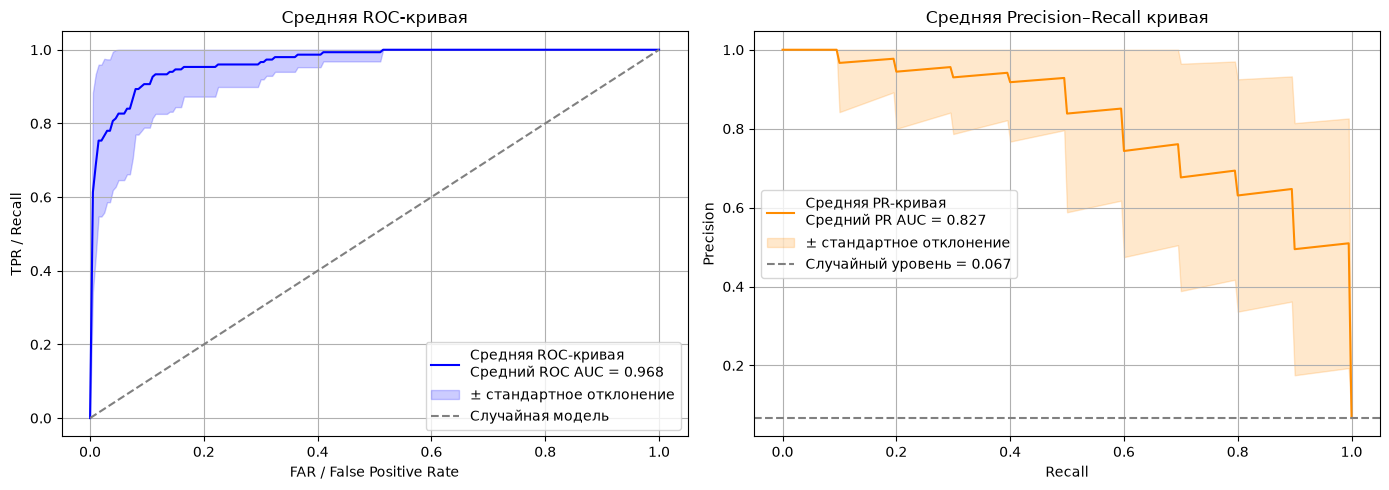

In [106]:
, model_id=2))
# для тестовой
#metrics_table, summary_table = (run_all_users_analysis(user_folders, "test", filt=0, model_id=2))